# Week 07: Shape of the sampling distribution of $\bar{x}$

**Course:** MATH7810 Python for Data Science (AY2026/27)

## Shape of the sampling distribution of $\bar x$

1. When sampling from a normally distributed population, the shape of the sampling distribution of $\bar{x}$ is normal, **whatever the value of $n$**.
2. When the population from which the samples are selected is **not** normally distributed, the central limit theorem says: for a large sample size ($n \geq 30$), the sampling distribution of $\bar{x}$ is **approximately normal**, whatever the shape of the population.

Section 1 uses one small sample size and only 20 samples, so each draw can be read. Section 2 uses many samples so the shape can be compared with a normal curve. That orange curve has mean $\mu$ and standard deviation $\sigma/\sqrt{n}$. It comes from the formula. It is not fitted to the bars.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
n_rep = 4000  # used in Section 2: how many samples, each contributing one x-bar

## 1. The population is normal

Cookie-package weights in the lecture are normal with mean 32 ounces and standard deviation 0.3 ounce. Because the population is normal, the sampling distribution of $\bar{x}$ is normal for every $n$, including a small one.

Here $n = 5$. We draw that sample **20 times**, print every draw, then the 20 sample means, then a histogram of those means.


In [ ]:
# Population: Normal(mu, sigma^2). Every package weight is one draw from this distribution.
mu = 32
sigma = 0.3

n = 5           # observations in one sample
n_times = 20    # how many such samples we draw

# Seed so these 20 draws are the same every time this cell is run.
rng = np.random.default_rng(37)

# 20 rows, 5 columns. Each row is one sample of size n = 5.
draws = rng.normal(loc=mu, scale=sigma, size=(n_times, n))
samples = pd.DataFrame(
    draws,  # This is the body of the table.
    columns=[f"x{i}" for i in range(1, n + 1)],
    index=[f"sample {i}" for i in range(1, n_times + 1)],
)

print("20 draws, each of size n = 5")
print(samples.round(3).to_string())

# Sample mean of one row: add its 5 weights and divide by n.
# One row produces one value of x-bar. Twenty rows produce twenty values.
xbar = draws.mean(axis=1)
means = pd.Series(xbar, index=samples.index, name="xbar")
print("\nSample mean of each draw")
print(means.round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(xbar, bins=8, color="#4c78a8", edgecolor="white")
ax.axvline(mu, color="#c45500", lw=2, label=f"population mean = {mu}")
ax.set_title(r"Histogram of 20 sample means, each with $n = 5$")
ax.set_xlabel(r"sample mean $\bar{x}$")
ax.set_ylabel("Count")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


In [ ]:
# Compare the 20 sample means with the cookie population.
# The average of the sample means is close to the population mean mu.
# The standard deviation of the sample means is close to sigma / sqrt(n),
# which is smaller than the population standard deviation sigma.

n = 5
average_of_means = xbar.mean()
sd_of_means = xbar.std(ddof=1)
se = sigma / np.sqrt(n)  # standard deviation of x-bar in the sampling distribution

print("population mean mu                         ", round(mu, 3))
print("average of the 20 sample means             ", round(average_of_means, 3))
print()
print("population standard deviation sigma        ", round(sigma, 3))
print("sigma / sqrt(n)                            ", round(se, 3))
print("standard deviation of the 20 sample means  ", round(sd_of_means, 3))

## 2. The population is not normal

A fair die is a discrete uniform population: the faces 1, 2, 3, 4, 5, and 6 are equally likely. That shape is flat, not a bell. The population mean is 3.5 and the population standard deviation is $\sqrt{35/12} \approx 1.708$.

The central limit theorem does not say that $\bar{x}$ is exactly normal. It says that when $n \geq 30$, the sampling distribution is approximately normal, even though one roll is not.


First 5 samples with n = 5. Each row is one sample. xbar is that row's mean.
          roll 1  roll 2  roll 3  roll 4  roll 5  xbar
sample 1       1       5       4       3       3   3.2
sample 2       6       1       5       2       1   3.0
sample 3       4       6       5       5       5   5.0
sample 4       5       4       1       6       3   3.8
sample 5       4       3       2       6       5   4.0
The histogram uses all 4000 sample means, not only these 5.

First 5 samples with n = 30. Each row is one sample. xbar is that row's mean.
          roll 1  roll 2  roll 3  roll 4  roll 5  roll 6  roll 7  roll 8  roll 9  roll 10  roll 11  roll 12  roll 13  roll 14  roll 15  roll 16  roll 17  roll 18  roll 19  roll 20  roll 21  roll 22  roll 23  roll 24  roll 25  roll 26  roll 27  roll 28  roll 29  roll 30   xbar
sample 1       1       5       2       5       4       2       3       1       5        2        3        1        3        3        2        6        2        2        4       

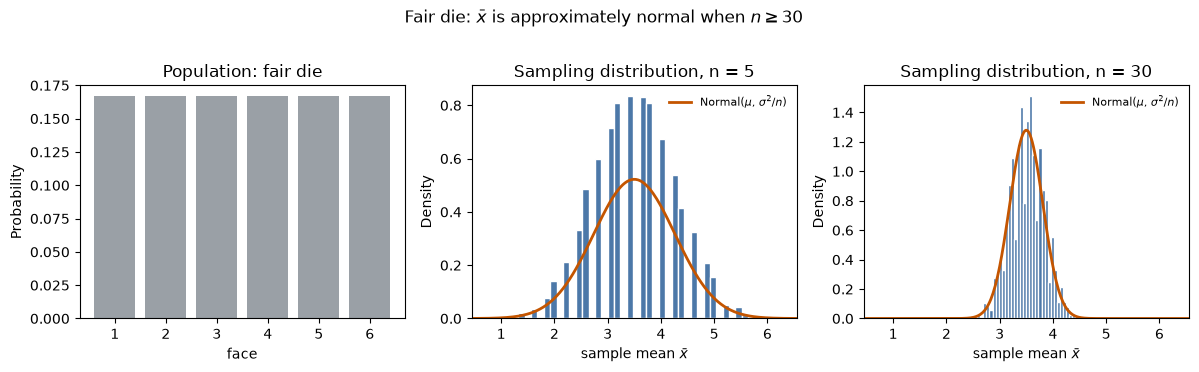

   n   mean of x-bar        mu   sd of x-bar   sigma/sqrt(n)
   5           3.480     3.500         0.760           0.764
  30           3.506     3.500         0.317           0.312


In [2]:
# Population: one roll of a fair die. Faces 1 through 6, each with probability 1/6.
faces = np.arange(1, 7)
mu = faces.mean()            # 3.5
sigma = faces.std(ddof=0)    # population sd, sqrt(35/12)

# n = 5 is below 30, so the theorem does not claim a normal shape yet.
# n = 30 is the lecture's cutoff for "large".
sample_sizes = (5, 30)

# Each entry is one roll. One row is one sample of n rolls. The row mean is one x-bar.
# rolls keeps the faces. xbars keeps only the mean of each row.
# Seed here so these rolls do not depend on how many random numbers earlier cells used.
rng = np.random.default_rng(42)
rolls = {
    n: rng.integers(1, 7, size=(n_rep, n))
    for n in sample_sizes
}
xbars = {n: rolls[n].mean(axis=1) for n in sample_sizes}

# Print a few rows so the step is visible. The histogram below uses all n_rep means.
n_show = 5
for n in sample_sizes:
    shown = pd.DataFrame(
        rolls[n][:n_show],
        columns=[f"roll {i}" for i in range(1, n + 1)],
        index=[f"sample {i}" for i in range(1, n_show + 1)],
    )
    shown["xbar"] = xbars[n][:n_show].round(3)
    print(f"First {n_show} samples with n = {n}. Each row is one sample. xbar is that row's mean.")
    print(shown.to_string())
    print(f"The histogram uses all {n_rep} sample means, not only these {n_show}.\n")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

ax = axes[0]
ax.bar(faces, np.full(len(faces), 1 / 6), color="#9aa0a6", width=0.8)
ax.set_xticks(faces)
ax.set_title("Population: fair die")
ax.set_xlabel("face")
ax.set_ylabel("Probability")

# Shared horizontal scale from the wider sampling distribution (n = 5),
# so the eye can see that n = 30 is a narrower bell.
se_wide = sigma / np.sqrt(min(sample_sizes))
x_left = mu - 4 * se_wide
x_right = mu + 4 * se_wide
x_shared = np.linspace(x_left, x_right, 300)

for ax, n in zip(axes[1:], sample_sizes):
    means = xbars[n]
    se = sigma / np.sqrt(n)  # standard deviation of x-bar
    # density=True puts the histogram on the same vertical scale as a pdf (area 1).
    ax.hist(means, bins=40, density=True, color="#4c78a8", edgecolor="white")
    ax.plot(
        x_shared,
        stats.norm.pdf(x_shared, loc=mu, scale=se),
        color="#c45500",
        lw=2,
        label=r"Normal($\mu$, $\sigma^2/n$)",
    )
    ax.set_xlim(x_left, x_right)
    ax.set_title(f"Sampling distribution, n = {n}")
    ax.set_xlabel(r"sample mean $\bar{x}$")
    ax.set_ylabel("Density")
    ax.legend(frameon=False, fontsize=8)

fig.suptitle(r"Fair die: $\bar{x}$ is approximately normal when $n \geq 30$", y=1.02)
fig.tight_layout()
plt.show()

print(f"{'n':>4}  {'mean of x-bar':>14}  {'mu':>8}  {'sd of x-bar':>12}  {'sigma/sqrt(n)':>14}")
for n in sample_sizes:
    means = xbars[n]
    print(
        f"{n:4d}  {means.mean():14.3f}  {mu:8.3f}  {means.std(ddof=1):12.3f}  "
        f"{sigma / np.sqrt(n):14.3f}"
    )


## What to point at

**Normal population.** Each printed row is one sample of 5 weights. The number under it is that row's sample mean, one value of $\bar{x}$. The histogram is those 20 means. They sit near 32. Twenty means are only a first look, so the bars will not form a smooth bell. The sampling distribution is still normal at $n = 5$, because the population is normal. A larger $n$ is not required for the shape.

**Fair die.** The population panel is flat: each face has probability $1/6$. That is not a normal curve. At $n = 5$ the sample means already pile up near 3.5, but the normal curve is only a rough match and the bars are still coarse. At $n = 30$ the bars sit close to the orange curve, and the spread is about $\sigma/\sqrt{n}$, smaller than the spread of one roll. "Approximately" means close, not identical.
